# 03. Нулевые распределения для положения России на осях

**Вторая статья, третий ноутбук.** Он отвечает на вопрос, который нельзя решить по кэшу из 97 слов: насколько отклонение России от сравнительного среднего на осях «деспотизм — свобода» и «варварство — цивилизация» отличается от того, что получается на **случайных осях**, построенных по тем же правилам из **полного словаря** каждой модели.

**Что нужно.** Полные модели Pedrazzini (2023) в `data/models_2023/` или в каталоге из переменной окружения `LWM_MODEL_DIR_2023` (то же, что требует `00_prepare_data.ipynb`). Ноутбук запускается из корня репозитория, **не изменяет** модели и кэш и не зависит от других ноутбуков. Время: порядка 5–15 минут, оперативная память: около 2 ГБ.

**Что считается.**

1. Контроль: при заданных осях ноутбук заново воспроизводит табл. 4 и сверяет её с `results/tables/05_table4_for_article.csv`.
2. Три варианта случайных осей. В каждом **одни и те же слова используются во всех двенадцати десятилетиях**, поэтому сохраняется постоянство лексики, а значит и возможные устойчивые особенности самого слова *russia*.
   * `matched` — слова подбираются **по частоте** слот за слотом (слово на месте *despotism* заменяется словом близкой частоты, и так для каждого из 20 слов) из всего словаря;
   * `local` — то же, но пул ограничен **семантической окрестностью** слов оси (ближайшие K слов к центроиду оси), то есть случайные оси строятся из лексики того же «района» пространства;
   * `shuffle` — те же 20 слов, но с **перетасованными парами и ориентацией** (разрушает антонимическую структуру, лексика остаётся).
3. Сравнение наблюдаемых величин с нулевыми: по каждому десятилетию и в целом (среднее 1830–1910-х, постоянство знака, число крайних рангов, сдвиг оси цивилизации с 1800–1810-х на 1830–1860-е, «сближение» 1870-х, перемена 1910-х).
4. **Широкая группа государств** (около 60 названий вместо десяти): место России среди них, z-оценка и процентиль. Это проверка того, не зависит ли результат от выбора десяти стран.
5. Проверка частотной зависимости проекций среди государственных названий.

**Как читать.** Нулевое распределение показывает, насколько большим бывает отклонение России на **произвольной** оси из лексики такого типа. Оно не является доверительным интервалом для настоящей оси и не учитывает шум обучения моделей (он требует повторных обучений, которых нет). Если наблюдаемая величина не выходит за пределы нулевого разброса, оснований считать её специфичной именно для оси свободы или цивилизации нет.

In [1]:
import os, gc, time, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from lwm import config as C, tools as T

if not (Path.cwd() / "lwm" / "tools.py").is_file():
    raise RuntimeError("Запустите Jupyter из корня репозитория (там, где лежит папка lwm).")
T.set_style()
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 200)

# ----------------------------- параметры -----------------------------------
SEED = 20261122
M_SETS = 4000          # число случайных осей на вариант и на ось
MIN_COUNT = 50         # минимальная частота слова в КАЖДОЙ модели для попадания в пул
TOL = 0.15             # допуск по log10 относительной частоты при подборе слова на слот
MIN_ELIGIBLE = 40      # минимальное число подходящих слов на слот (иначе берутся ближайшие по частоте)
K_LOCAL = 2500         # размер семантической окрестности для варианта local
USE_SPELLCHECK = True  # оставлять в пуле только слова английского словаря (меньше OCR-мусора)
REUSE_CACHE = True     # использовать сохранённые выборки из полных моделей, если они есть
CACHE_NPZ = C.ROOT / "data" / "cache_null" / "null_candidates.npz"
N_PAIR_SIM = 200_000   # число пар осей для распределения числа крайних рангов по обеим осям

rng = np.random.default_rng(SEED)
PERIODS = C.PERIODS; LABS = T.decade_labels(); ND = len(PERIODS)
IDX_LATE = list(range(3, 12))      # 1830-е ... 1910-е
IDX_EARLY = [0, 1]                 # 1800-е, 1810-е
IDX_MID = [3, 4, 5, 6]             # 1830-е ... 1860-е
I1860, I1870, I1900, I1910 = 6, 7, 10, 11
print("Модели:", C.MODEL_DIR)

Модели: C:\Users\Admin\Documents\GitHub\british-press-semantic-change\data\models_2023


## 1. Словари и исключения

Пул случайных слов строится из слов, которые есть **во всех двенадцати моделях** с частотой не ниже `MIN_COUNT`. Из пула исключаются слова самих осей и их однокоренные формы (по первым шести буквам), названия стран и национальностей, слова вокруг России. Широкая группа государств хранится отдельно и допускает отсутствие названия в части десятилетий.

In [2]:
REAL = {ax: [w for pair in C.working_pairs(ax) for w in pair] for ax in C.WORKING_AXES}   # порядок: нег., поз., нег., поз., ...
ALL_AXIS_WORDS = sorted({w for spec in C.AXES.values() for pair in spec["pairs"] for w in pair})
COUNTRIES = list(C.COUNTRIES); assert COUNTRIES[0] == C.RUSSIA

STATES = ["russia", "france", "austria", "prussia", "germany", "turkey", "spain", "italy", "england", "britain", "america",
          "portugal", "holland", "netherlands", "belgium", "denmark", "sweden", "norway", "switzerland", "greece", "poland",
          "hungary", "bohemia", "saxony", "bavaria", "hanover", "sardinia", "naples", "sicily", "tuscany", "piedmont",
          "wurtemberg", "baden", "lombardy", "persia", "india", "china", "japan", "egypt", "abyssinia", "morocco", "tunis",
          "algeria", "afghanistan", "siam", "burmah", "mexico", "brazil", "peru", "chili", "venezuela", "colombia", "cuba",
          "hayti", "canada", "australia", "ireland", "scotland", "wales", "finland", "servia", "roumania", "bulgaria",
          "montenegro", "arabia", "syria", "tibet", "nepal", "korea"]
STATES = list(dict.fromkeys(STATES))
NATIONAL = ["russian", "russians", "french", "german", "germans", "british", "english", "englishmen", "austrian", "austrians",
            "turkish", "turks", "turk", "prussian", "prussians", "italian", "italians", "spanish", "american", "americans",
            "ottoman", "czar", "tsar", "czars", "tsars", "czarina", "autocrat", "autocracy", "emperor", "empress",
            "muscovite", "muscovy", "cossack", "cossacks", "petersburg", "moscow", "siberia", "kremlin", "russias"]
EXCLUDE = set(ALL_AXIS_WORDS) | set(COUNTRIES) | set(STATES) | set(NATIONAL) | set(C.all_words())
STEMS = {w[:6] for w in ALL_AXIS_WORDS if len(w) >= 6} | {w for w in ALL_AXIS_WORDS if len(w) < 6}
FORCE = sorted(set(sum(REAL.values(), [])) | set(COUNTRIES))     # должны быть во всех моделях
print(f"Слов в реальных осях: { {k: len(v) for k, v in REAL.items()} }, стран: {len(COUNTRIES)}, государств в широкой группе: {len(STATES)}")

Слов в реальных осях: {'liberty': 20, 'civilisation': 20}, стран: 11, государств в широкой группе: 69


## 2. Извлечение векторов из полных моделей

Два прохода по моделям (по одной в памяти). Первый находит слова, общие для всех десятилетий. Второй извлекает их нормированные векторы и частоты. Результат сохраняется в `data/cache_null/null_candidates.npz` (десятки мегабайт), чтобы не читать модели заново.

In [3]:
def _scan(p):
    model = T.load_model(p); m = model.wv
    if "count" not in m.expandos:
        raise RuntimeError(f"{p}: в модели нет частот (wv.expandos['count']).")
    cnt = np.asarray(m.expandos["count"], dtype=np.int64)
    total = getattr(model, "corpus_total_words", None)
    total = int(total) if total else int(cnt.sum())
    ok = {k for k, c in zip(m.index_to_key, cnt) if c >= MIN_COUNT and k.isascii() and k.isalpha() and len(k) >= 3}
    force_present = {w for w in FORCE if w in m.key_to_index}
    return ok, force_present, total

def _extract(p, words):
    model = T.load_model(p); m = model.wv
    cnt = np.asarray(m.expandos["count"], dtype=np.int64)
    idx = np.array([m.key_to_index[w] for w in words])
    X = np.asarray(m.vectors[idx], dtype=np.float32); X /= np.linalg.norm(X, axis=1, keepdims=True)
    # широкая группа: векторы и частоты там, где слово есть
    SV = np.zeros((len(STATES), X.shape[1]), np.float32); SC = np.zeros(len(STATES), np.int64)
    for i, w in enumerate(STATES):
        if w in m.key_to_index:
            v = np.asarray(m.vectors[m.key_to_index[w]], dtype=np.float32); SV[i] = v / np.linalg.norm(v); SC[i] = cnt[m.key_to_index[w]]
    return X, cnt[idx], SV, SC

t0 = time.time()
if REUSE_CACHE and CACHE_NPZ.is_file():
    z = np.load(CACHE_NPZ, allow_pickle=True)
    WORDS = list(z["words"]); U = z["U"]; CNT = z["CNT"]; TOT = z["TOT"]; SV = z["SV"]; SC = z["SC"]
    assert list(z["states"]) == STATES and list(z["periods"]) == PERIODS and int(z["min_count"]) == MIN_COUNT, "Кэш устарел: удалите файл или поставьте REUSE_CACHE=False"
    print("Загружено из", CACHE_NPZ)
else:
    inter = None; totals = []
    for p in PERIODS:
        ok, fp, total = _scan(p)
        miss = set(FORCE) - fp
        if miss: raise ValueError(f"{p}: нет обязательных слов {sorted(miss)}")
        inter = ok if inter is None else inter & ok
        totals.append(total); print(p, "кандидатов в модели:", len(ok), "общих пока:", len(inter))
    WORDS = sorted(inter | set(FORCE)); TOT = np.array(totals, dtype=np.int64)
    U = np.zeros((ND, len(WORDS), C.MODEL_DIM), np.float32); CNT = np.zeros((ND, len(WORDS)), np.int64)
    SV = np.zeros((ND, len(STATES), C.MODEL_DIM), np.float32); SC = np.zeros((ND, len(STATES)), np.int64)
    for d, p in enumerate(PERIODS):
        U[d], CNT[d], SV[d], SC[d] = _extract(p, WORDS); gc.collect()
    CACHE_NPZ.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(CACHE_NPZ, words=np.array(WORDS), U=U, CNT=CNT, TOT=TOT, SV=SV, SC=SC, states=np.array(STATES),
                        periods=np.array(PERIODS), min_count=MIN_COUNT)
    print("Сохранено", CACHE_NPZ)
print(f"Слов во всех моделях: {len(WORDS)}, время {time.time()-t0:.0f} с")
IX = {w: i for i, w in enumerate(WORDS)}
UC = [U[d][[IX[c] for c in COUNTRIES]] for d in range(ND)]        # (11, 200) на десятилетие, Россия первая
RF = np.log10(CNT / TOT[:, None]); RF_MEAN = RF.mean(axis=0)      # log10 относительной частоты

1800s кандидатов в модели: 61498 общих пока: 61498
1810s кандидатов в модели: 67544 общих пока: 52312
1820s кандидатов в модели: 65611 общих пока: 48228
1830s кандидатов в модели: 50076 общих пока: 37137
1840s кандидатов в модели: 97653 общих пока: 37085
1850s кандидатов в модели: 116655 общих пока: 37009
1860s кандидатов в модели: 104127 общих пока: 36835
1870s кандидатов в модели: 101812 общих пока: 36208
1880s кандидатов в модели: 119583 общих пока: 36047
1890s кандидатов в модели: 111228 общих пока: 35749
1900s кандидатов в модели: 84223 общих пока: 34578
1910s кандидатов в модели: 65291 общих пока: 32706
Сохранено C:\Users\Admin\Documents\GitHub\british-press-semantic-change\data\cache_null\null_candidates.npz
Слов во всех моделях: 32706, время 58 с


## 3. Контроль: воспроизведение табл. 4

Оси строятся по тем же формулам, что в `lwm.tools` (нормированная разность `pos − neg` по паре, нормировка, среднее, нормировка). Если здесь есть расхождения, дальнейшие результаты интерпретировать нельзя.

In [4]:
def axis_from_slots(Ud, W):
    # Ud: (n, 200) нормированные векторы, W: (m, 20) индексы слов в порядке нег., поз., нег., поз., ...
    X = Ud[W]; D = X[:, 1::2, :] - X[:, 0::2, :]
    D = D / np.linalg.norm(D, axis=2, keepdims=True)
    a = D.mean(axis=1); return a / np.linalg.norm(a, axis=1, keepdims=True)

def russia_stats(A, d):
    P = A @ UC[d].T
    return P[:, 0] - P[:, 1:].mean(axis=1), (P < P[:, [0]]).sum(axis=1) + 1, P

REAL_IDX = {ax: np.array([IX[w] for w in ws]) for ax, ws in REAL.items()}
OBS_D = {}; OBS_R = {}
for ax in C.WORKING_AXES:
    OBS_D[ax] = np.zeros(ND); OBS_R[ax] = np.zeros(ND, int)
    for d in range(ND):
        dd, rr, _ = russia_stats(axis_from_slots(U[d], REAL_IDX[ax][None, :]), d)
        OBS_D[ax][d] = dd[0]; OBS_R[ax][d] = rr[0]

t4 = pd.read_csv(C.TAB_DIR / "05_table4_for_article.csv", encoding="utf-8-sig")
num = lambda s: float(str(s).replace("−", "-").replace(",", "."))
chk = []
for ax, col in zip(C.WORKING_AXES, ["Свобода", "Цивилизация"]):
    ref = t4[f"{col}: разность"].map(num).to_numpy(); rr = t4[f"{col}: ранг"].astype(int).to_numpy()
    chk.append((ax, float(np.max(np.abs(ref - OBS_D[ax]))), bool((rr == OBS_R[ax]).all())))
print("Максимальное расхождение с табл. 4 (разности) и совпадение рангов:", chk)
if any(c[1] > 6e-5 or not c[2] for c in chk):
    warnings.warn("РАСХОЖДЕНИЕ с табл. 4: проверьте версию моделей и конфигурацию. Результаты ниже ненадёжны.")
else:
    print("Контроль пройден: табл. 4 воспроизведена.")

Максимальное расхождение с табл. 4 (разности) и совпадение рангов: [('liberty', 4.549787044524911e-05, True), ('civilisation', 4.772739410401072e-05, True)]
Контроль пройден: табл. 4 воспроизведена.


## 4. Три варианта случайных осей

Для каждой рабочей оси генерируется `M_SETS` наборов из 20 слов. Набор **один и тот же во всех десятилетиях**, меняются только векторы (модели разные). Для каждого набора и десятилетия считаются отклонение России от среднего десяти стран и её ранг, как в табл. 4.

In [5]:
# ------------------------- пул -----------------------------------
base_mask = np.array([(w not in EXCLUDE) and (w[:6] not in STEMS) and (w not in STEMS) for w in WORDS])
if USE_SPELLCHECK:
    try:
        from spellchecker import SpellChecker
        known = SpellChecker().known([w for w, ok in zip(WORDS, base_mask) if ok])
        base_mask &= np.array([w in known for w in WORDS])
        print("Фильтр по словарю включён")
    except Exception as e:
        print("Фильтр по словарю недоступен:", e)
POOL = np.where(base_mask)[0]
print("Размер пула:", len(POOL))

def eligible_for(target_rf, pool_idx):
    d = np.abs(RF_MEAN[pool_idx] - target_rf); e = pool_idx[d <= TOL]
    return e if len(e) >= MIN_ELIGIBLE else pool_idx[np.argsort(d)[:MIN_ELIGIBLE]]

def sample_matched(real_idx, pool_idx, M):
    elig = [eligible_for(RF_MEAN[i], pool_idx) for i in real_idx]
    W = np.empty((M, len(real_idx)), dtype=np.int64)
    for j, e in enumerate(elig):
        w = rng.choice(e, M)
        for _ in range(1000):                       # слот за слотом: слово не должно повторяться в наборе
            bad = (w[:, None] == W[:, :j]).any(axis=1) if j else np.zeros(M, bool)
            if not bad.any(): break
            w[bad] = rng.choice(e, int(bad.sum()))
        else:
            raise RuntimeError("Не удалось убрать повторы слов в наборах: слишком узкий пул")
        W[:, j] = w
    return W, elig

def local_pool(real_idx, pool_idx):
    sims = np.zeros(len(WORDS))
    for d in range(ND):
        c = U[d][real_idx].mean(axis=0); c /= np.linalg.norm(c); sims += U[d] @ c
    return pool_idx[np.argsort(-sims[pool_idx])[:K_LOCAL]]

def run_null(W, chunk=1000):
    Dm = np.empty((len(W), ND), np.float32); Rk = np.empty((len(W), ND), np.int8)
    for d in range(ND):
        for s in range(0, len(W), chunk):
            dd, rr, _ = russia_stats(axis_from_slots(U[d], W[s:s + chunk]), d)
            Dm[s:s + chunk, d] = dd; Rk[s:s + chunk, d] = rr
    return Dm, Rk

NUL = {}; POOLINFO = []
t0 = time.time()
for ax in C.WORKING_AXES:
    ri = REAL_IDX[ax]
    W, elig = sample_matched(ri, POOL, M_SETS); NUL[(ax, "matched")] = run_null(W)
    POOLINFO.append((ax, "matched", len(POOL), int(np.median([len(e) for e in elig]))))
    LP = local_pool(ri, POOL)
    W, elig = sample_matched(ri, LP, M_SETS); NUL[(ax, "local")] = run_null(W)
    POOLINFO.append((ax, "local", len(LP), int(np.median([len(e) for e in elig]))))
    W = np.argsort(rng.random((M_SETS, len(ri))), axis=1); W = ri[W]; NUL[(ax, "shuffle")] = run_null(W)
    POOLINFO.append((ax, "shuffle", len(ri), len(ri)))
    print(ax, "готово, с:", round(time.time() - t0))
print(pd.DataFrame(POOLINFO, columns=["ось", "вариант", "размер пула", "медиана подходящих слов на слот"]))

Фильтр по словарю включён
Размер пула: 23547
liberty готово, с: 2
civilisation готово, с: 4
            ось  вариант  размер пула  медиана подходящих слов на слот
0       liberty  matched        23547                             3331
1       liberty    local         2500                              344
2       liberty  shuffle           20                               20
3  civilisation  matched        23547                             3307
4  civilisation    local         2500                              310
5  civilisation  shuffle           20                               20


## 5. Десятилетие за десятилетием

`p_abs` — доля случайных осей, на которых отклонение России по модулю не меньше наблюдаемого (знак случайной оси произволен, поэтому сравнивается модуль). Используется поправка (k + 1)/(M + 1), поэтому минимальное значение равно примерно 1/M, а не нулю. `p_extreme` — доля случайных осей, на которых Россия занимает первое или одиннадцатое место.

In [6]:
rows = []
for ax in C.WORKING_AXES:
    for var in ["matched", "local", "shuffle"]:
        Dm, Rk = NUL[(ax, var)]
        for d in range(ND):
            x = Dm[:, d]
            rows.append(dict(ось=ax, вариант=var, десятилетие=LABS[d], наблюдается=OBS_D[ax][d], ранг=OBS_R[ax][d],
                             sd_нуля=float(x.std()), q95_модуля=float(np.quantile(np.abs(x), 0.95)),
                             p_abs=float(((np.abs(x) >= abs(OBS_D[ax][d])).sum() + 1) / (len(x) + 1)),
                             p_extreme=float(((Rk[:, d] == 1) | (Rk[:, d] == 11)).mean()),
                             p_rank_как_наблюдаемый=float((Rk[:, d] == OBS_R[ax][d]).mean())))
PER = pd.DataFrame(rows)
T.save_table(PER.round(4), "06_null_per_decade", index=False)
for ax in C.WORKING_AXES:
    print("Ось:", C.AXES[ax]["label"])
    display(PER[PER.ось == ax].pivot(index="десятилетие", columns="вариант", values="p_abs").reindex(LABS)
            .assign(наблюдается=OBS_D[ax], ранг=OBS_R[ax]).round(3))

Сохранено: results/tables/06_null_per_decade.csv
Ось: деспотизм – свобода


вариант,local,matched,shuffle,наблюдается,ранг
десятилетие,,,,,
1800-е,0.777,0.793,0.796,-0.014,5
1810-е,0.110,0.147,0.195,-0.067,1
1820-е,0.852,0.857,0.826,0.010,7
1830-е,0.163,0.183,0.118,-0.065,1
1840-е,0.159,0.103,0.100,-0.083,2
1850-е,0.608,0.491,0.563,-0.028,5
1860-е,0.008,0.004,0.015,-0.113,1
1870-е,0.371,0.335,0.419,-0.037,4
1880-е,0.090,0.046,0.136,-0.097,1


Ось: варварство – цивилизация


вариант,local,matched,shuffle,наблюдается,ранг
десятилетие,,,,,
1800-е,0.187,0.199,0.244,0.070,10
1810-е,0.384,0.412,0.488,0.038,9
1820-е,0.892,0.891,0.897,-0.007,5
1830-е,0.223,0.238,0.164,-0.058,3
1840-е,0.057,0.056,0.083,-0.088,1
1850-е,0.173,0.120,0.150,-0.064,2
1860-е,0.225,0.264,0.400,-0.048,3
1870-е,0.913,0.921,0.886,0.004,6
1880-е,0.026,0.021,0.066,-0.113,1


## 6. Совокупные проверки

Все статистики инвариантны к знаку случайной оси (сравниваются модули либо величины вида «сколько десятилетий с одним знаком»). Лексика одна и та же во всех десятилетиях, поэтому нулевое распределение **учитывает постоянные особенности слова *russia***, чего не делал расчёт по кэшу из 97 слов.

In [7]:
def tests_for_axis(ax, var):
    Dm, Rk = NUL[(ax, var)]; o = OBS_D[ax]; orank = OBS_R[ax]
    out = []
    def add(name, obs, null, kind="abs"):
        if kind == "abs": p = float(((np.abs(null) >= abs(obs)).sum() + 1) / (len(null) + 1)); extra = float(np.quantile(np.abs(null), 0.95))
        else: p = float(((null >= obs).sum() + 1) / (len(null) + 1)); extra = float(np.quantile(null, 0.95))
        out.append(dict(ось=ax, вариант=var, проверка=name, наблюдается=float(obs), порог_95=extra, p=p))
    add("среднее отклонение 1830-е...1910-е", o[IDX_LATE].mean(), Dm[:, IDX_LATE].mean(axis=1))
    neg = (Dm[:, IDX_LATE] < 0).sum(axis=1); k_null = np.maximum(neg, len(IDX_LATE) - neg)
    neg_o = int((o[IDX_LATE] < 0).sum()); add("постоянство знака 1830-е...1910-е (из 9)", max(neg_o, 9 - neg_o), k_null, kind="ge")
    ext_null = ((Rk == 1) | (Rk == 11)).sum(axis=1); ext_obs = int(np.isin(orank, [1, 11]).sum())
    add("число крайних рангов (из 12 десятилетий)", ext_obs, ext_null, kind="ge")
    add("сдвиг: 1800–1810-е минус 1830–1860-е", o[IDX_EARLY].mean() - o[IDX_MID].mean(), Dm[:, IDX_EARLY].mean(axis=1) - Dm[:, IDX_MID].mean(axis=1))
    add("изменение 1870-е минус 1860-е", o[I1870] - o[I1860], Dm[:, I1870] - Dm[:, I1860])
    add("изменение 1910-е минус 1900-е", o[I1910] - o[I1900], Dm[:, I1910] - Dm[:, I1900])
    return out

agg = []
for ax in C.WORKING_AXES:
    for var in ["matched", "local", "shuffle"]: agg += tests_for_axis(ax, var)
# число крайних рангов по обеим осям вместе
for var in ["matched", "local", "shuffle"]:
    e = [((NUL[(ax, var)][1] == 1) | (NUL[(ax, var)][1] == 11)).sum(axis=1) for ax in C.WORKING_AXES]
    i1 = rng.integers(0, M_SETS, N_PAIR_SIM); i2 = rng.integers(0, M_SETS, N_PAIR_SIM); tot = e[0][i1] + e[1][i2]
    obs = sum(int(np.isin(OBS_R[ax], [1, 11]).sum()) for ax in C.WORKING_AXES)
    agg.append(dict(ось="обе", вариант=var, проверка="число крайних рангов (из 24)", наблюдается=float(obs),
                    порог_95=float(np.quantile(tot, 0.95)), p=float(((tot >= obs).sum() + 1) / (len(tot) + 1))))
AGG = pd.DataFrame(agg)
T.save_table(AGG.round(5), "06_null_aggregate", index=False)
display(AGG.pivot_table(index=["ось", "проверка"], columns="вариант", values="p").round(4))
display(AGG[AGG.вариант == "matched"][["ось", "проверка", "наблюдается", "порог_95"]].round(4))

Сохранено: results/tables/06_null_aggregate.csv


вариант                                                 local  matched  shuffle
ось          проверка                                                          
civilisation изменение 1870-е минус 1860-е             0.2297   0.2754   0.3387
             изменение 1910-е минус 1900-е             0.5311   0.5339   0.5036
             постоянство знака 1830-е...1910-е (из 9)  0.2939   0.2539   0.3402
             сдвиг: 1800–1810-е минус 1830–1860-е      0.0042   0.0062   0.0722
             среднее отклонение 1830-е...1910-е        0.0452   0.0380   0.0570
             число крайних рангов (из 12 десятилетий)  0.4749   0.4799   0.4934
liberty      изменение 1870-е минус 1860-е             0.0772   0.0975   0.2637
             изменение 1910-е минус 1900-е             0.3174   0.2919   0.4541
             постоянство знака 1830-е...1910-е (из 9)  0.1905   0.0950   0.1765
             сдвиг: 1800–1810-е минус 1830–1860-е      0.4896   0.4616   0.4844
             среднее отклонение 1830-е...1910-е        0.0242   0.0110   0.0380
             число крайних рангов (из 12 десятилетий)  0.0365   0.0245   0.0682
обе          число крайних рангов (из 24)              0.0549   0.0504   0.0870

,ось,проверка,наблюдается,порог_95
0,liberty,среднее отклонение 1830-е...1910-е,-0.0746,0.0566
1,liberty,постоянство знака 1830-е...1910-е (из 9),9.0000,9.0000
2,liberty,число крайних рангов (из 12 десятилетий),5.0000,4.0000
3,liberty,сдвиг: 1800–1810-е минус 1830–1860-е,0.0315,0.0849
4,liberty,изменение 1870-е минус 1860-е,0.0760,0.0888
5,liberty,изменение 1910-е минус 1900-е,0.0446,0.0843
18,civilisation,среднее отклонение 1830-е...1910-е,-0.0584,0.0545
19,civilisation,постоянство знака 1830-е...1910-е (из 9),8.0000,9.0000
20,civilisation,число крайних рангов (из 12 десятилетий),2.0000,4.0000
21,civilisation,сдвиг: 1800–1810-е минус 1830–1860-е,0.1185,0.0837


## 7. Широкая группа государств

Вместо десяти названий берётся всё, что есть в списке `STATES` и в данной модели с частотой не ниже `MIN_COUNT`. Для России считаются место среди государств, процентиль, z-оценка (стандартизация внутри модели, поэтому величины сопоставимы между десятилетиями) и отклонение от среднего всех остальных названий. Для частотной проверки используется регрессия проекции на log-частоту внутри десятилетия, затем z-оценка остатка России.

In [8]:
def wide_rows(ax):
    rows = []
    for d in range(ND):
        a = axis_from_slots(U[d], REAL_IDX[ax][None, :])[0]
        present = np.where(SC[d] >= MIN_COUNT)[0]; names = [STATES[i] for i in present]
        pr = SV[d][present] @ a; lc = np.log10(SC[d][present]); ri = names.index(C.RUSSIA)
        z = (pr[ri] - pr.mean()) / pr.std(ddof=1)
        others = np.delete(pr, ri)
        rho = pd.Series(pr).corr(pd.Series(lc), method="spearman")
        b = np.polyfit(lc, pr, 1); res = pr - np.polyval(b, lc); zr = (res[ri] - res.mean()) / res.std(ddof=1)
        rows.append(dict(ось=ax, десятилетие=LABS[d], n_государств=len(names), проекция_России=pr[ri],
                         место_снизу=int((pr < pr[ri]).sum() + 1), процентиль=float((pr < pr[ri]).mean()),
                         z=z, отклонение_от_всех_остальных=pr[ri] - others.mean(), отклонение_табл4=OBS_D[ax][d],
                         rho_logчастота=rho, z_после_поправки_на_частоту=zr, частота_России=int(SC[d][present][ri]),
                         самые_низкие=", ".join(np.array(names)[np.argsort(pr)[:3]]), самые_высокие=", ".join(np.array(names)[np.argsort(-pr)[:3]])))
    return pd.DataFrame(rows)

WIDE = pd.concat([wide_rows(ax) for ax in C.WORKING_AXES], ignore_index=True)
T.save_table(WIDE.round(4), "06_wide_states", index=False)
for ax in C.WORKING_AXES:
    print("Ось:", C.AXES[ax]["label"]); display(WIDE[WIDE.ось == ax].drop(columns="ось").round(3))
print("Медиана rho(проекция, log-частота) по десятилетиям:", WIDE.groupby("ось").rho_logчастота.median().round(2).to_dict(),
      "| доля rho>0:", round(float((WIDE.rho_logчастота > 0).mean()), 2))

Сохранено: results/tables/06_wide_states.csv
Ось: деспотизм – свобода


,десятилетие,n_государств,проекция_России,место_снизу,процентиль,z,отклонение_от_всех_остальных,отклонение_табл4,rho_logчастота,z_после_поправки_на_частоту,частота_России,самые_низкие,самые_высокие
0,1800-е,60,-0.108,15,0.233,-0.634,-0.053,-0.014,0.237,-0.865,11214,"persia, france, greece","ireland, japan, nepal"
1,1810-е,60,-0.111,6,0.083,-1.438,-0.087,-0.067,0.173,-1.681,17007,"servia, bulgaria, hungary","siam, norway, finland"
2,1820-е,62,-0.044,29,0.452,-0.061,-0.005,0.010,0.240,-0.368,23548,"syria, italy, lombardy","colombia, britain, canada"
3,1830-е,62,-0.100,1,0.000,-1.867,-0.094,-0.065,0.053,-1.920,18762,"russia, bulgaria, hanover","hayti, naples, colombia"
4,1840-е,66,-0.050,12,0.167,-1.131,-0.070,-0.083,0.244,-1.460,29021,"afghanistan, bulgaria, spain","saxony, piedmont, canada"
5,1850-е,69,-0.048,16,0.217,-0.580,-0.032,-0.028,0.297,-1.018,104606,"lombardy, tuscany, naples","canada, australia, scotland"
6,1860-е,69,-0.027,16,0.217,-0.809,-0.054,-0.113,0.547,-1.454,36286,"syria, abyssinia, algeria","britain, england, denmark"
7,1870-е,69,0.003,30,0.420,-0.204,-0.012,-0.037,0.264,-0.569,27807,"arabia, lombardy, persia","colombia, america, canada"
8,1880-е,69,-0.140,8,0.101,-1.274,-0.081,-0.097,0.353,-1.831,20929,"algeria, bohemia, poland","canada, scotland, australia"
9,1890-е,69,-0.109,11,0.145,-1.060,-0.071,-0.087,0.409,-1.750,13301,"bohemia, sicily, sardinia","chili, scotland, canada"


Ось: варварство – цивилизация


,десятилетие,n_государств,проекция_России,место_снизу,процентиль,z,отклонение_от_всех_остальных,отклонение_табл4,rho_logчастота,z_после_поправки_на_частоту,частота_России,самые_низкие,самые_высокие
12,1800-е,60,0.064,51,0.833,0.976,0.063,0.070,0.320,0.701,11214,"spain, lombardy, tunis","scotland, nepal, sweden"
13,1810-е,60,0.050,52,0.850,1.040,0.068,0.038,0.593,0.400,17007,"egypt, tunis, morocco","britain, india, ireland"
14,1820-е,62,0.004,31,0.484,0.155,0.010,-0.007,0.414,-0.415,23548,"tunis, syria, tibet","britain, colombia, norway"
15,1830-е,62,-0.039,17,0.258,-0.594,-0.032,-0.058,0.542,-1.535,18762,"finland, algeria, persia","saxony, scotland, britain"
16,1840-е,66,-0.040,18,0.258,-0.589,-0.041,-0.088,0.455,-1.163,29021,"bulgaria, afghanistan, burmah","netherlands, belgium, germany"
17,1850-е,69,-0.069,12,0.159,-0.926,-0.057,-0.064,0.362,-1.507,104606,"afghanistan, persia, montenegro","norway, brazil, belgium"
18,1860-е,69,0.020,41,0.580,0.145,0.009,-0.048,0.591,-0.474,36286,"tibet, montenegro, bohemia","india, england, norway"
19,1870-е,69,-0.019,45,0.638,0.434,0.023,0.004,0.428,-0.152,27807,"abyssinia, lombardy, bohemia","netherlands, wales, australia"
20,1880-е,69,-0.151,8,0.101,-1.069,-0.077,-0.113,0.531,-1.950,20929,"hayti, arabia, lombardy","australia, canada, hanover"
21,1890-е,69,-0.080,35,0.493,-0.208,-0.016,-0.065,0.514,-0.982,13301,"turkey, poland, arabia","britain, germany, england"


Медиана rho(проекция, log-частота) по десятилетиям: {'civilisation': 0.52, 'liberty': 0.28} | доля rho>0: 1.0


## 8. Иллюстрации

Левый рисунок: отклонение России на настоящих осях (как на рис. 1) на фоне 95-процентной границы модуля для случайных осей (`matched` и `local`). Правый: z-оценка России среди широкой группы государств.

Сохранено: results/figures/06_null_band.png


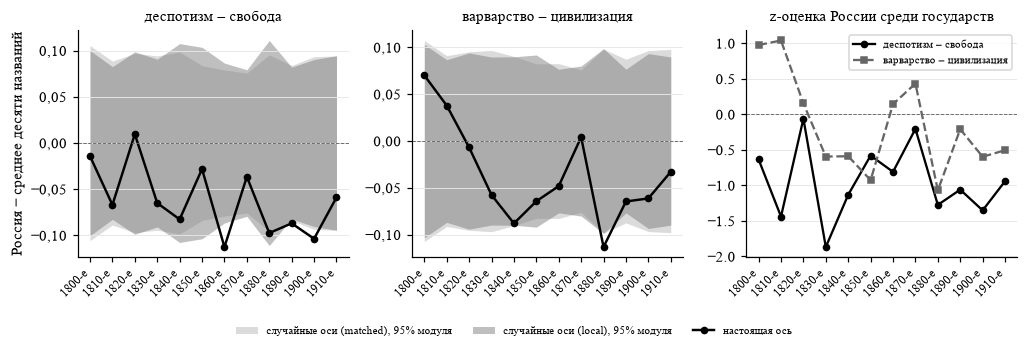

In [9]:
fig, axs = plt.subplots(1, 3, figsize=(24 / 2.54, 8 / 2.54), sharex=True)
x = np.arange(ND)
for k, ax in enumerate(C.WORKING_AXES):
    a = axs[k]
    for var, col, al in [("matched", "0.75", 0.55), ("local", "0.45", 0.45)]:
        q = PER[(PER.ось == ax) & (PER.вариант == var)].set_index("десятилетие").reindex(LABS).q95_модуля.to_numpy()
        a.fill_between(x, -q, q, color=col, alpha=al, lw=0, label=f"случайные оси ({var}), 95% модуля")
    a.plot(x, OBS_D[ax], "o-", color="black", lw=1.6, ms=4, label="настоящая ось")
    a.axhline(0, color="0.4", lw=0.6, ls="--"); a.set_title(C.AXES[ax]["label"], fontsize=10)
    a.set_xticks(x); a.set_xticklabels(LABS, rotation=45, ha="right", fontsize=8); a.yaxis.set_major_formatter(T.COMMA)
axs[0].set_ylabel("Россия − среднее десяти названий")
h, l = axs[0].get_legend_handles_labels()
for ax, ls, mk in zip(C.WORKING_AXES, ["-", "--"], ["o", "s"]):
    axs[2].plot(x, WIDE[WIDE.ось == ax].z.to_numpy(), ls, marker=mk, ms=4, color="black" if ls == "-" else "0.4", label=C.AXES[ax]["label"])
axs[2].axhline(0, color="0.4", lw=0.6, ls="--"); axs[2].set_title("z-оценка России среди государств", fontsize=10)
axs[2].set_xticks(x); axs[2].set_xticklabels(LABS, rotation=45, ha="right", fontsize=8); axs[2].legend(fontsize=7)
fig.legend(h, l, loc="lower center", ncol=3, fontsize=7, frameon=False)
fig.tight_layout(rect=(0, 0.07, 1, 1)); T.save_fig(fig, "06_null_band"); plt.show()

## 9. Сводка для пересылки

Следующая ячейка печатает компактную сводку. Скопируйте её вывод, а также приложите файлы `results/tables/06_null_per_decade.csv`, `06_null_aggregate.csv`, `06_wide_states.csv` и рисунок `results/figures/06_null_band.png`.

In [10]:
print("=== СВОДКА ===")
print("Параметры:", dict(SEED=SEED, M_SETS=M_SETS, MIN_COUNT=MIN_COUNT, TOL=TOL, K_LOCAL=K_LOCAL, SPELL=USE_SPELLCHECK, pool=len(POOL), words_all_models=len(WORDS)))
print("Контроль табл. 4:", chk)
print("\nСовокупные проверки (p):")
print(AGG.pivot_table(index=["ось", "проверка"], columns="вариант", values="p").round(4).to_string())
print("\nНаблюдаемые значения и 95%-пороги (matched):")
print(AGG[AGG.вариант == "matched"][["ось", "проверка", "наблюдается", "порог_95"]].round(4).to_string(index=False))
print("\nМедианный sd нуля по вариантам и осям:")
print(PER.groupby(["ось", "вариант"]).sd_нуля.median().round(4).to_string())
print("\nДесятилетия с p_abs < 0.05:")
print(PER[PER.p_abs < 0.05][["ось", "вариант", "десятилетие", "наблюдается", "p_abs"]].round(3).to_string(index=False))
print("\nШирокая группа, z России и процентиль:")
print(WIDE[["ось", "десятилетие", "n_государств", "место_снизу", "процентиль", "z", "z_после_поправки_на_частоту", "rho_logчастота"]].round(2).to_string(index=False))

=== СВОДКА ===
Параметры: {'SEED': 20261122, 'M_SETS': 4000, 'MIN_COUNT': 50, 'TOL': 0.15, 'K_LOCAL': 2500, 'SPELL': True, 'pool': 23547, 'words_all_models': 32706}
Контроль табл. 4: [('liberty', 4.549787044524911e-05, True), ('civilisation', 4.772739410401072e-05, True)]

Совокупные проверки (p):
вариант                                                 local  matched  shuffle
ось          проверка                                                          
civilisation изменение 1870-е минус 1860-е             0.2297   0.2754   0.3387
             изменение 1910-е минус 1900-е             0.5311   0.5339   0.5036
             постоянство знака 1830-е...1910-е (из 9)  0.2939   0.2539   0.3402
             сдвиг: 1800–1810-е минус 1830–1860-е      0.0042   0.0062   0.0722
             среднее отклонение 1830-е...1910-е        0.0452   0.0380   0.0570
             число крайних рангов (из 12 десятилетий)  0.4749   0.4799   0.4934
liberty      изменение 1870-е минус 1860-е             0.0772

### Как интерпретировать результаты

* **p_abs малое (например < 0,05) в большинстве десятилетий и во всех трёх вариантах.** Положение России на настоящих осях отличается от того, что дают произвольные оси из лексики того же типа и частоты. Это поддерживает вывод о специфичности осей.
* **p_abs велико.** В этом десятилетии отклонение России сопоставимо с шумом выбора оси, и интерпретировать его нельзя.
* **Совокупные p малы при больших p отдельных десятилетий.** Постоянное положение ниже среднего статистически устойчиво, но отдельные десятилетия по отдельности ничего не доказывают.
* **Отличие `matched` от `local`.** Если p в `local` заметно больше, значит, часть эффекта объясняется тем, что Россия отличается от остальных названий на любой оси из «политической» части пространства, а не на оси оценки.
* **`shuffle` показывает вклад антонимической структуры.** Если p в `shuffle` велики, а в `matched` малы, различие создаёт сам состав слов, а не парность.
* **Широкая группа.** Если z России остаётся отрицательным и сходным по величине при ~60 названиях, результат не зависит от выбора десяти стран. Положительная корреляция проекции с частотой означает, что частые названия систематически выше, поэтому z после поправки на частоту надёжнее.